# Семинар 2

**Данные:** PBMC 3k (периферическая кровь человека, 10x Genomics)

В первом семинаре мы получили матрицу экспрессии, провели QC, нормализацию, выбрали 2000 высоковариабельных генов (HVG) и построили PCA. Теперь мы хотим ответить на два разных вопроса:

1. **Какие клетки образуют группы?** Для этого строим граф ближайших соседей и применяем Leiden.
2. **Как показать тысячи клеток на одном двумерном графике?** Для этого используем UMAP или t-SNE.

> **Главное различие:** Leiden определяет кластеры **на графе соседства**, построенном по координатам PCA. UMAP и t-SNE нужны прежде всего для **визуализации**, а не для установления кластеров.

## 0. Подготовка окружения

Можно продолжить работу в окружении `sc_pbmc` из первого семинара. Для Leiden нужны **`leidenalg` и `python-igraph`**

```bash
mamba create -n sc_pbmc -c conda-forge \
    python=3.11 "scanpy>=1.11,<2" scikit-misc leidenalg python-igraph \
    umap-learn scikit-learn pandas numpy scipy matplotlib \
    jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Если окружение уже создано, достаточно:

```bash
mamba activate sc_pbmc
mamba install -c conda-forge leidenalg python-igraph umap-learn scikit-learn -y
```


In [4]:
pip install scanpy leidenalg scikit-misc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 39.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 71.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 85.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 98.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.2 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [scanpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [5]:
from pathlib import Path
import scanpy as sc
import leidenalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 0.1. Продолжаем первый семинар на тех же данных PBMC 3k

- Если `data/pbmc3k_after_pca.h5ad` уже существует, загрузим готовую обработанную матрицу.
- Иначе прочитаем исходную матрицу из `data/filtered_gene_bc_matrices/hg19/` (папка из предыдущего занятия). Если её нет, Scanpy скачает PBMC 3k из своей коллекции данных и мы повторим **те же** пороги QC, HVG и PCA.

Исходные данные: [10x Genomics PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0). Функция загрузки: [`sc.datasets.pbmc3k`](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html).

In [ ]:
#cache = Path("data/pbmc3k_after_pca.h5ad")
#raw_folder = Path("data/filtered_gene_bc_matrices/hg19")


#adata = sc.read_10x_mtx(raw_folder, var_names="gene_symbols", make_unique=True)

adata = sc.datasets.pbmc3k()

In [ ]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [ ]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500) &
    (adata.obs["pct_counts_mt"] < 5)
].copy()


In [ ]:
adata.layers["counts"] = adata.X.copy()

In [ ]:
sc.pp.highly_variable_genes(
    adata, layer="counts", flavor="seurat_v3", n_top_genes=2000
)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

# 1. Повторение PCA

В первом семинаре каждой клетке сопоставили вектор экспрессии генов. PCA заменяет исходные признаки координатами в новом базисе:

$$
\mathbf{x}_i=(PC_{i1},PC_{i2},\dots,PC_{ip})\in\mathbb{R}^{p}.
$$

В `adata.obsm["X_pca"]` каждая **строка соответствует клетке**, каждый **столбец — компоненте PCA**.

Евклидово расстояние между клетками $i$ и $j$ в пространстве первых $p$ компонент:

$$
d(i,j)=\left\|\mathbf{x}_i-\mathbf{x}_j\right\|_2
=\sqrt{\sum_{r=1}^{p}\left(PC_{ir}-PC_{jr}\right)^2}.
$$


In [ ]:
X_pca = adata.obsm["X_pca"]
print("Первые 5 клеток, первые 5 координат PCA:")
display(pd.DataFrame(X_pca[:5, :5], index=adata.obs_names[:5],
                     columns=[f"PC{i}" for i in range(1, 6)]))

Первые 5 клеток, первые 5 координат PCA:


,PC1,PC2,PC3,PC4,PC5
index,,,,,
AAACATACAACCAC-1,-4.729656,-0.732485,-1.319631,0.310005,-0.847269
AAACATTGAGCTAC-1,-0.771727,7.029477,4.317773,-1.829984,-1.793581
AAACATTGATCAGC-1,-3.747784,-2.741884,-2.263518,-3.970395,-1.300419
AAACCGTGCTTCCG-1,13.714365,0.483030,1.592937,-0.528195,1.163329
AAACCGTGTATGCG-1,-3.042009,-4.998953,7.369839,5.631863,1.837182


# 2. От точек к графу: kNN

**Граф** — это набор вершин и рёбер. В нашей задаче:

- вершина = одна клетка;
- ребро $i\to j$ = клетка $j$ входит в число $k$ ближайших соседей клетки $i$;
- вес ребра = численная оценка близости клеток.

Сначала алгоритм ищет **kNN — k nearest neighbors**. Это отношение в общем случае **направленное**: клетка B может входить в 2 ближайших соседа A, но клетка A может не входить в 2 ближайших соседа B.

Для графовой кластеризации обычно используют **ненаправленный взвешенный граф**. Простейшая симметризация бинарного графа — $A_{ij}^{\mathrm{sym}}=\max(A_{ij},A_{ji})$.

В Scanpy при `method="umap"` расчёт **весов** устроен сложнее: используются локально масштабированные степени принадлежности к соседству с последующим объединением направленных связей. Это **не** просто обратное евклидово расстояние.


### kNN на реальных клетках

В Scanpy используется **двухэтапная процедура**:

1. Найти ближайших соседей по координатам первых 30 PC (`n_pcs=30`).
2. По этим соседям вычислить веса связей между клетками (`connectivities`).

**Где хранятся результаты?**

| Поле AnnData | Что означает |
|---|---|
| `adata.obsm["X_pca"]` | Координаты клеток в PCA |
| `adata.obsp["distances"]` | Разреженная матрица найденных расстояний |
| `adata.obsp["connectivities"]` | Разреженная, симметричная матрица весов связей |
| `adata.uns["neighbors"]` | Параметры построения графа и ссылки на матрицы |

**Важно:** `n_neighbors=15` — локальный параметр поиска соседей. После симметризации у вершины может оказаться **больше 15 ненулевых связей**.

In [ ]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    metric="euclidean",
    method="umap",
    random_state=42,
)

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'

In [ ]:
G = adata.obsp["connectivities"].tocsr()
D = adata.obsp["distances"].tocsr()

In [ ]:
print("Граф connectivities:", G.shape, "ненулевых элементов:", G.nnz)

print("Матрица distances:", D.shape, "ненулевых элементов:", D.nnz)

Граф connectivities: (2638, 2638) ненулевых элементов: 58162
Матрица distances: (2638, 2638) ненулевых элементов: 36932


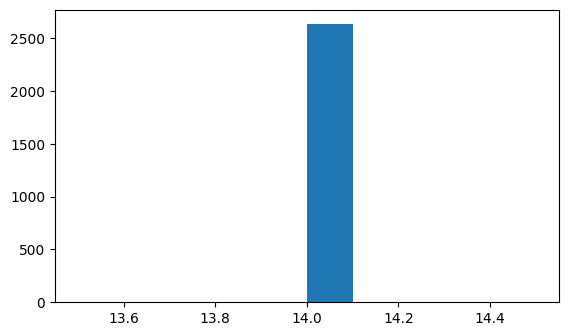

Минимум / медиана / максимум степеней: 14 14.0 14


In [ ]:
degree = np.asarray((D > 0).sum(axis=1)).ravel()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(degree, bins=10)
plt.show()

print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

In [ ]:
from scipy.sparse.csgraph import connected_components

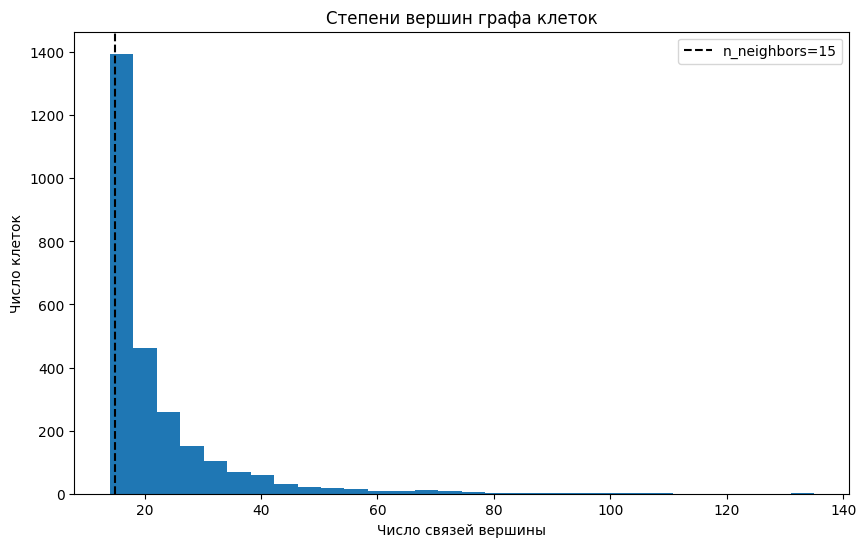

Число компонент связности: 1
Минимум / медиана / максимум степеней: 14 18.0 135


In [ ]:
degree = np.asarray((G > 0).sum(axis=1)).ravel()
components, labels_components = connected_components(G, directed=False)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(degree, bins=30)
ax.axvline(15, ls="--", color="black", label="n_neighbors=15")
ax.set(xlabel="Число связей вершины", ylabel="Число клеток",
       title="Степени вершин графа клеток")
ax.legend()
plt.show()
print("Число компонент связности:", components)
print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

# 3. Графовая кластеризация: Louvain → Leiden

**Кластеризация** — разбиение объектов на группы. Но «хорошая группа» должна иметь математическое определение.

- В методах типа k-means группа — набор точек, близких к общему центроиду.
- В графовых методах **сообщество** — группа вершин, которые связаны друг с другом сильнее, чем ожидалось бы при случайном соединении вершин по подходящей нулевой модели.

## 3.1. Модулярность: что оптимизирует алгоритм

Рассмотрим **ненаправленный граф** с матрицей весов $A=(A_{ij})$. Обозначим:

- $A_{ij}$ — вес ребра между вершинами $i$ и $j$;
- $k_i=\sum_j A_{ij}$ — взвешенная степень вершины $i$;
- $2m=\sum_i k_i$ — сумма весов рёбер, посчитанных по двум концам;
- $c_i$ — номер сообщества вершины $i$;
- $\mathbf{1}(c_i=c_j)$ равен единице, когда вершины в одной группе.

Одна из функций качества разбиения — **модулярность с параметром разрешения $\gamma$**:

$$
Q_{\gamma}=\frac{1}{2m}\sum_{i,j}
\left(A_{ij}-\gamma\frac{k_i k_j}{2m}\right)
\mathbf{1}(c_i=c_j).
$$

**Как понимать формулу:**

- $A_{ij}$ — наблюдаемый вес связи;
- $k_i k_j/(2m)$ — ожидаемый вес связи в модели случайного графа, сохраняющей ожидаемые степени вершин;
- в сумму попадают только пары вершин **из одной группы**;
- алгоритм пытается найти разбиение с **высоким значением $Q_\gamma$**.

$\gamma$ отвечает за масштаб: при большем $\gamma$ крупные сообщества сильнее «штрафуются», поэтому на практике часто появляются более мелкие кластеры. **Но число кластеров не обязано расти строго монотонно** из-за устройства графа и эвристической оптимизации.

## 3.2. Louvain и Leiden: чем они отличаются

**Louvain (2008):**

1. Стартует с отдельных сообществ (каждая вершина сама по себе).
2. По очереди переносит вершины между соседними сообществами, если растёт функция качества.
3. Объединяет сообщества в новые супервершины и повторяет оптимизацию.

**Проблема:** в отдельных случаях найденное сообщество может иметь плохую внутреннюю связность или даже быть несвязным.

**Leiden (2019)** добавляет **этап уточнения (refinement)** сообщества до агрегации. В результате алгоритм устраняет известную проблему несвязных сообществ Louvain и при сходимости предоставляет более сильные гарантии внутренней связности. Это **не означает**, что любой кластер Leiden биологически однороден.


Статья: [Traag, Waltman & van Eck, 2019 — From Louvain to Leiden](https://doi.org/10.1038/s41598-019-41695-z).

## 3.3. Leiden на PBMC 3k

Запустим Leiden несколько раз на **одном и том же графе**. Вызовы не используют координаты UMAP.

/tmp/ipykernel_670/1703150331.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
/tmp/ipykernel_670/1703150331.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1.0, key_added="leiden_

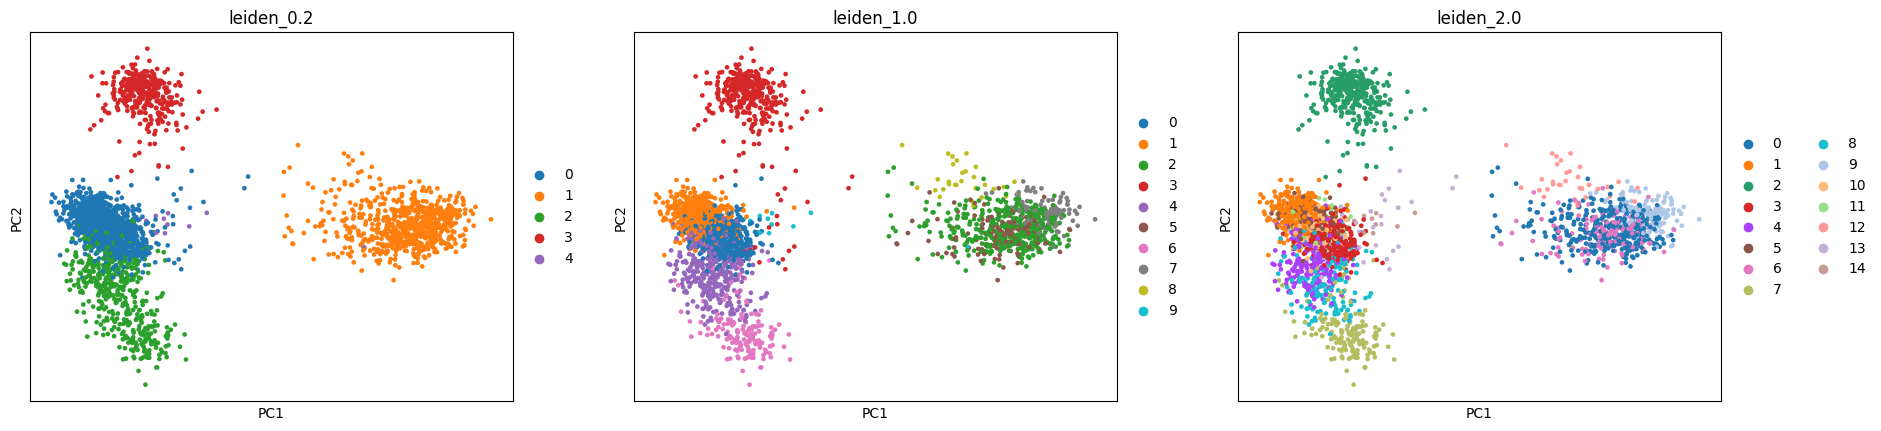

leiden_1.0
0    548
1    541
2    378
3    360
4    349
5    157
6    156
7    107
8     30
9     12
Name: count, dtype: int64


<Axes: xlabel='leiden_1.0'>

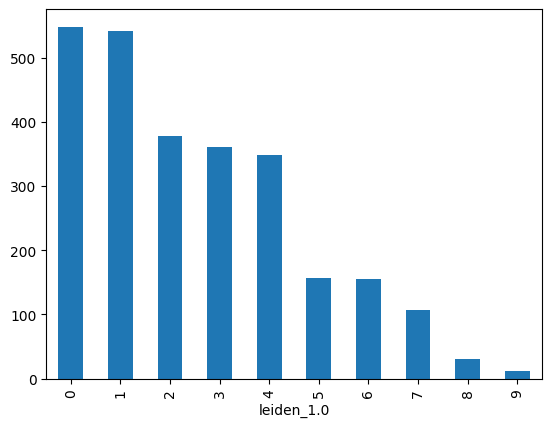

In [ ]:
sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0")
sc.tl.leiden(adata, resolution=2.0, key_added="leiden_2.0")

sc.pl.pca(
    adata,
    color=["leiden_0.2", "leiden_1.0", "leiden_2.0"],
    ncols=3
)
# Посмотрим, сколько получилось кластеров
print(adata.obs["leiden_1.0"].value_counts())
adata.obs["leiden_1.0"].value_counts().sort_index().plot.bar()

# 4. Переход из 30 измерений в два: t-SNE и UMAP

## 4.1. t-SNE: сохраняем вероятности соседства

Идея t-SNE: описать, насколько клетка $j$ является соседом клетки $i$, **вероятностью**, а затем подобрать на плоскости такую картинку, чтобы отношения соседства были похожими.

В высокоразмерном пространстве PCA условные вероятности определяются расстояниями:

$$
p_{j\mid i}=\frac{\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_j\|^2}{2\sigma_i^2}\right)}
{\sum_{k\ne i}\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_k\|^2}{2\sigma_i^2}\right)},\quad p_{i\mid i}=0.
$$

Далее строятся симметричные $p_{ij}=(p_{j\mid i}+p_{i\mid j})/(2n)$.

На двумерной карте используются тяжёлые хвосты распределения Стьюдента:

$$
q_{ij}=\frac{(1+\|\mathbf y_i-\mathbf y_j\|^2)^{-1}}
{\sum_{k\ne \ell}(1+\|\mathbf y_k-\mathbf y_\ell\|^2)^{-1}}.
$$

Подбираем координаты $\mathbf y_i$, минимизируя **KL-дивергенцию**:

$$
D_{\mathrm{KL}}(P\|Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$

**Смысл:** большие $p_{ij}$ «требуют», чтобы на карте $q_{ij}$ тоже были большими. Тяжёлые хвосты помогают разнести точки, которые не являются соседями.

`perplexity` управляет эффективным масштабом локального соседства: $\operatorname{Perp}(P_i)=2^{H(P_i)}$, где энтропия считается с логарифмом по основанию 2. Это **не точное число соседей** и не число кластеров.

## 4.2. UMAP: сохраняем взвешенное локальное соседство

UMAP начинает с соседей, строит **взвешенный граф** локального соседства и ищет координаты $\mathbf y_i$ на плоскости, при которых локальные связи остаются похожими.

В упрощённой записи направленные веса близости оцениваются как

$$
w_{j\mid i}=\exp\left[-\frac{\max\{0,d(i,j)-\rho_i\}}{\sigma_i}\right],
$$

где $\rho_i$ — локальное расстояние до ближайшего ненулевого соседа, $\sigma_i$ — локальный масштаб. Вес может затем объединяться с обратным $w_{i\mid j}$ по правилу

$$
w_{ij}=w_{j\mid i}+w_{i\mid j}-w_{j\mid i}w_{i\mid j}.
$$

На плоскости близость приближается функцией вида

$$
\hat w_{ij}=\frac{1}{1+a\|\mathbf y_i-\mathbf y_j\|^{2b}},
$$

где $a,b$ зависят от настроек формы кривой. **Идея функции потерь** — кросс-энтропия между весами связей исходного графа и весами на плоскости:

$$
\mathcal L=-\sum_{i<j}\left[
 w_{ij}\log\hat w_{ij}+(1-w_{ij})\log(1-\hat w_{ij})\right].
$$

Реальная оптимизация использует приближения, включая отрицательное семплирование несоседних пар. Формула выше описывает **математическую цель**, а не буквальный полный перебор всех пар в каждой итерации.

Параметры:

- **`n_neighbors`** (в `sc.pp.neighbors`) определяет масштаб исходных локальных отношений.
- **`min_dist`** (в `sc.tl.umap`) регулирует, насколько плотно точки могут располагаться на карте.
- **`random_state`** задаёт воспроизводимый случайный старт/другие случайные шаги алгоритма.

## Полезно посмотреть
* https://github.com/NikolayOskolkov/HowUMAPWorks/blob/master/HowUMAPWorks.ipynb   
* https://pair-code.github.io/understanding-umap/

# 5.Leiden + UMAP + t-SNE

**Цель:** выполнить обе визуализации для **одних и тех же клеток и одних и тех же меток Leiden**. Только так можно корректно сравнивать полученные картинки.

`sc.tl.umap()` использует уже построенный граф соседства. `sc.tl.tsne()` ниже явно использует первые 30 PC.

In [ ]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)

sc.tl.tsne(adata, use_rep="X_pca", n_pcs=30, perplexity=30, random_state=42)

In [ ]:
print("UMAP:", adata.obsm["X_umap"].shape,
      "t-SNE:", adata.obsm["X_tsne"].shape)

UMAP: (2638, 2) t-SNE: (2638, 2)


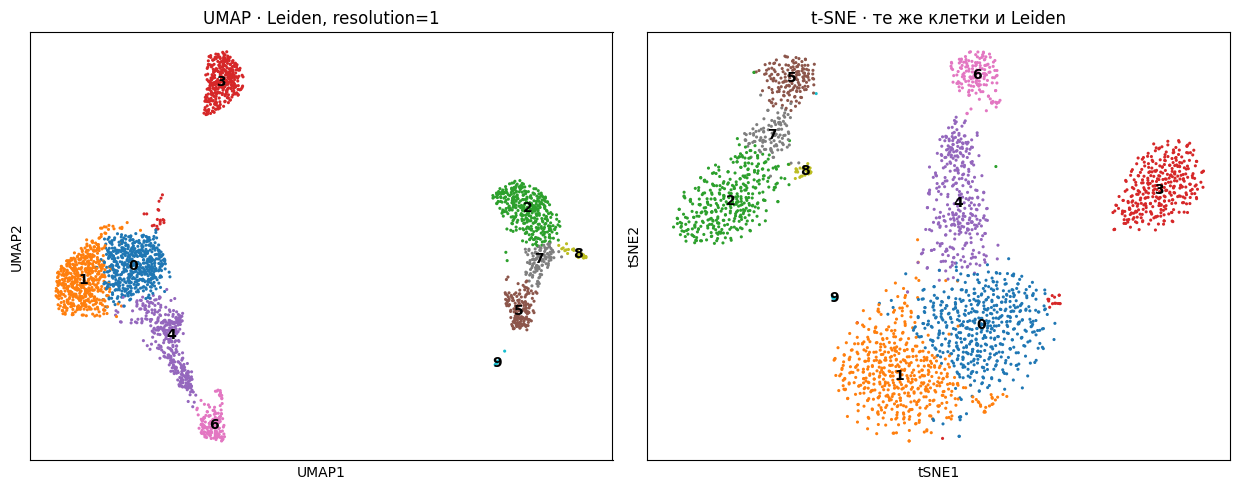

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
sc.pl.umap(adata, color="leiden_1.0", legend_loc="on data",
           title="UMAP · Leiden, resolution=1", ax=axes[0], show=False, size=20)
sc.pl.tsne(adata, color="leiden_1.0", legend_loc="on data",
           title="t-SNE · те же клетки и Leiden", ax=axes[1], show=False, size=20)
plt.tight_layout()
plt.show()

## 5.1. Проверяем, что картинка не равна кластеризации

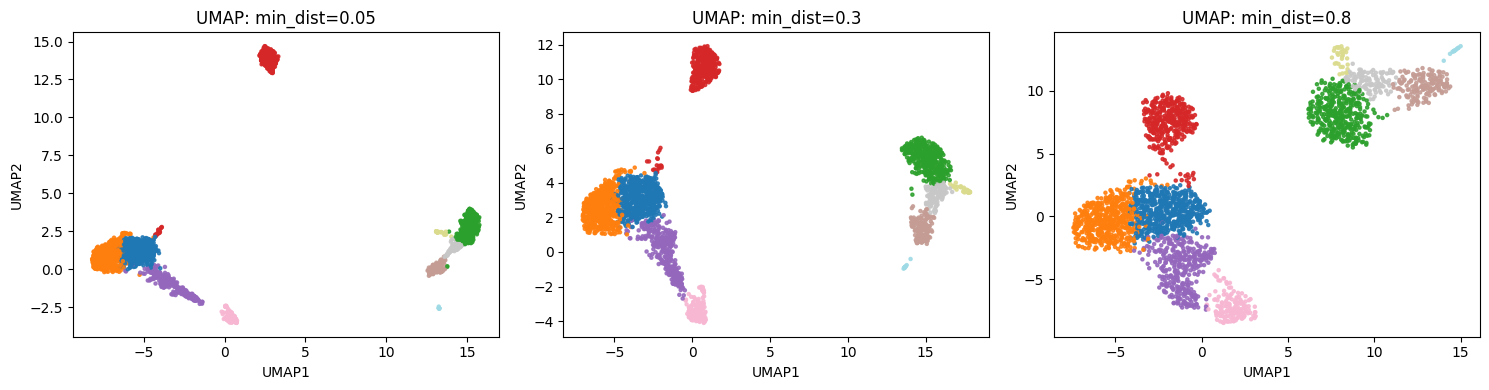

In [ ]:
from copy import deepcopy
original_umap_params = deepcopy(adata.uns.get("umap", {}))
original_embedding = adata.obsm["X_umap"].copy()
original_labels = adata.obs["leiden_1.0"].copy()

embeddings = {0.3: original_embedding}
for value in (0.05, 0.8):
    sc.tl.umap(adata, min_dist=value, random_state=42)
    embeddings[value] = adata.obsm["X_umap"].copy()

adata.obsm["X_umap"] = original_embedding  # возвращаем основной UMAP
adata.uns["umap"] = original_umap_params  # и исходные параметры в AnnData
assert original_labels.equals(adata.obs["leiden_1.0"])

labels = adata.obs["leiden_1.0"].cat.codes.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (value, xy) in zip(axes, sorted(embeddings.items())):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab20", s=5, alpha=0.85)
    ax.set(title=f"UMAP: min_dist={value}", xlabel="UMAP1", ylabel="UMAP2")
plt.tight_layout()
plt.show()

## 5.2. Проверка через биологию

Окрасим UMAP по известным генам-маркерам: `CD3D` (T-клетки), `MS4A1` (B-клетки), `NKG7` (NK-клетки), `LST1` (моноциты).

In [ ]:
markers = [g for g in ["CD3D", "MS4A1", "NKG7", "LST1"] if g in adata.var_names]

In [ ]:
sc.pl.umap(adata, color=markers, ncols=2, size=20)

## 5.3. Сохраняем результаты для следующего занятия

В `.h5ad` сохраняются исходная матрица, `X_pca`, граф соседства, все варианты меток Leiden и основная визуализация `X_umap`/`X_tsne`. На следующем семинаре можно начать с аннотации кластеров, не повторяя вычисления.

In [ ]:
result_path = Path("data/pbmc3k_after_clustering.h5ad")
adata.write_h5ad(result_path, compression="gzip")

# Самостоятельная работа: модулярность и анализ scRNA-seq

## Задание 1. Посчитать модулярность вручную

На рисунке показан **неориентированный невзвешенный граф из 9 вершин**. Рёбра внутри сообщества проведены сплошными линиями, между сообществами — пунктирными.

![Граф из 9 вершин](seminar6_modularity_graph.png)

Сообщества: **A = {1, 2, 3}**, **B = {4, 5, 6}**, **C = {7, 8, 9}**.

1. Посчитайте общее число рёбер графа `m`.
2. Для каждого сообщества найдите `l_c` — число рёбер, оба конца которых находятся внутри сообщества, и `d_c` — сумму степеней его вершин (включая внешние связи).
3. По формуле ниже вычислите **модулярность разбиения вручную**, показав промежуточные вычисления:

   $$Q=\sum_{c=1}^{3}\left(\frac{l_c}{m}-\left(\frac{d_c}{2m}\right)^2\right).$$

4. Объясните словами, зачем из доли внутренних рёбер вычитается второй член. Что показывает положительное значение `Q`? Является ли `Q` вероятностью?

## Задание 2. Самостоятельный анализ клеток в Scanpy

**Выберите один** набор 10x Genomics (PBMC 3k не использовать):

- [Клетки сердца эмбриона мыши E18 (~1011 клеток)](https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки головного мозга эмбриона мыши E18 (~1301 клетка)](https://www.10xgenomics.com/datasets/1-k-brain-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки селезёнки мыши (~1119 клеток)](https://www.10xgenomics.com/datasets/splenocytes-from-c-57-bl-6-mice-1-k-cells-v-2-2-standard-4-0-0)

На странице набора загрузите **Feature / cell matrix HDF5 (filtered)** (для селезёнки — матрицу **Gene Expression**, а не V(D)J). Это счётчики UMI для баркодов, уже отобранных Cell Ranger; исходные пустые капли в эту матрицу не входят.

```python
import scanpy as sc
adata = sc.read_10x_h5("путь/к/скачанному_файлу.h5")
adata.var_names_make_unique()
```

**Проведите анализ**, используя методы Scanpy, изученные на семинарах:

1. **QC.** Посчитайте и покажите распределения количества UMI (`total_counts`), обнаруженных генов (`n_genes_by_counts`) и доли митохондриальных счётчиков (`pct_counts_mt`). Выберите пороги фильтрации клеток и генов, примените их и **объясните почему выбрали именно эти значения**. Укажите, сколько клеток осталось.
2. **Нормализация и HVG.** Выполните нормализацию, `log1p` и отбор высоковариабельных генов. Укажите число HVG и объясните, зачем их отбирают и почему выбранное количество разумно.
3. **PCA.** Постройте PCA. Выберите число главных компонент для дальнейшего анализа; объясните выбор, используя график доли объяснённой дисперсии.
4. **Граф и Leiden.** Постройте граф соседей, выполните кластеризацию Leiden. Укажите `n_neighbors`, `n_pcs`, `resolution`, число получившихся кластеров и число клеток в них. Объясните выбранные параметры.
5. **UMAP и t-SNE.** Постройте обе визуализации, раскрасив точки по меткам Leiden. Также раскрасьте PCA или UMAP по одной QC-метрике и по **двум выбранным известным генам**, если они есть в данных. Опишите, что видно и какие выводы сделать нельзя.
6. **Биологический вывод.** По нескольким предложениям объясните, какие клеточные популяции **предположительно** присутствуют в выбранной ткани. Обоснуйте предположение экспрессией выбранных генов; не называйте кластеры достоверно определёнными клеточными типами.

**Разрешено:** стандартные функции Scanpy для QC, фильтрации, нормализации, HVG, PCA, графа соседей, Leiden, UMAP и t-SNE; окраска графиков по кластерам, QC-метрикам и **заданным вручную** генам.

**Не использовать:** `sc.tl.rank_genes_groups`, `sc.tl.score_genes`, методы автоматической аннотации или другие ещё не изученные методы. Подбор генов можно сделать по литературе, без автоматического поиска маркеров.

**Что сдавать:** число и расчёт модулярности; Jupyter-ноутбук с анализом одного набора данных, графиками, числом клеток до/после QC, параметрами и краткими объяснениями сделанных решений. Не требуется получить «правильное» число кластеров.


Задание 1

1. Общее число ребер графа

m = 3+3+3+3 = 12 (3 в каждом сообществе и 3 между ними)

2. Посчитаем число ребер, находящихся внутри сообщества и сумму степеней вершин для каждого сообщества (А, В и С)

|     | $l_c$ | $d_c$     |
| --- | ----- | --------- |
| А   | 3     | 3+2+3 = 8 |
| В   | 3     | 3+2+3 = 8 |
| С   | 3     | 3+2+3 = 8 |

3. Теперь посчитаем модулярность разбиения

$$Q = \sum_{c=1}^3(\frac{l_c}{m}-(\frac{d_c}{2m})^2)$$
Заметим, что у всех трех сообществ значения $l$ и $d$ одинаковы - можно упростить выражение
$$Q=3(\frac{l}{m}-(\frac{d}{2m})^2) = 3(\frac{3}{12}-(\frac{8}{12*2})^2) =$$ $$=3(0.25 - (\frac{1}{3})^2)=0.75 - \frac{1}3 = \frac{5}{12}$$


4. Первый член показывает долю ребер, находящихся внутри сообщества, а второй - ожидаемую долю внутренних ребер, если бы граф был случайным. Мы вычитаем второй член, чтобы понять, насколько сообщество лучше, чем случайное ожидание.

Положительное значение Q означает, что внутри сообществ связей больше, чем можно было ожидать для случайного графа, то есть есть кластерная структура.

При этом Q не является вероятностью - она просто является статистической метрикой, показывающей качество разбиения

Для самостоятельной работы возьмем набор данных с клетками селезенки мыши

In [31]:
adata = sc.read_10x_h5("/content/sc5p_v2_mm_c57bl6_splenocyte_1k_filtered_feature_bc_matrix.h5")
adata.var_names_make_unique()

/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


Проведем QC (по митохондриальным генам - у мыши начинаются с mt)



In [32]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)


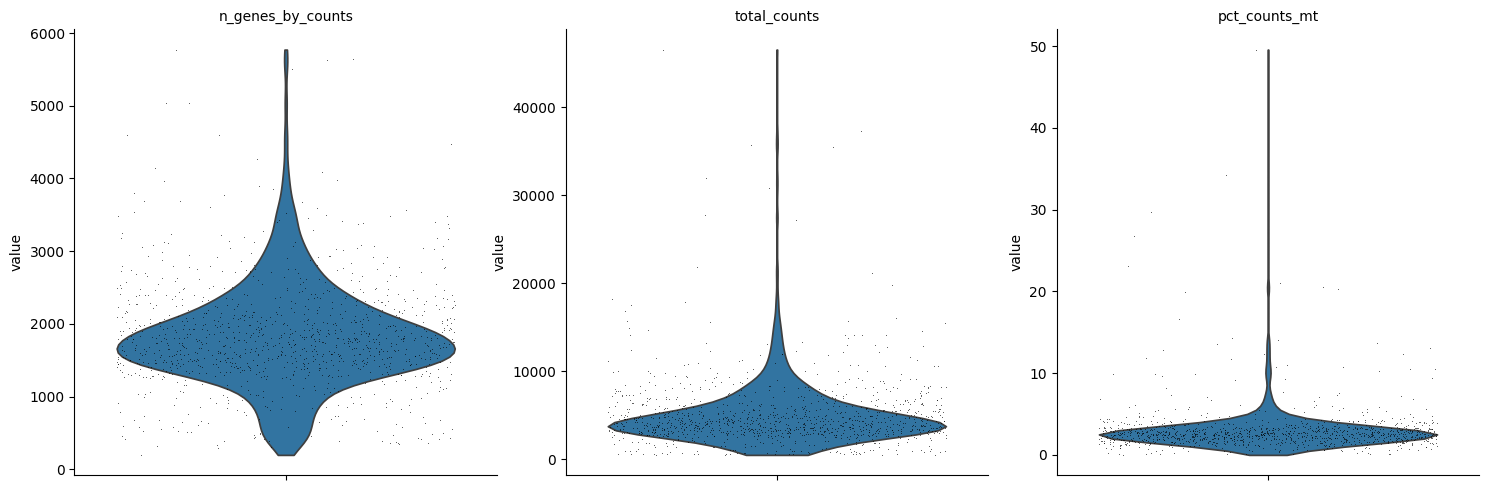

In [33]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.4, multi_panel=True, size=0.5)

Сделаем отсечку по числу генов сверху в 3000 а по митохондриальным генам в 7% - чуть выше, чем делали до этого, так как в селезенке очень много метаболически активных иммунных клеток, которые мы бы могли просто выбросить при QC, поэтому стоит убрать только явные выбросы, сделав порог более мягким.

Порог на минимальное число генов нужен чтобы отсеять пустые капли/дебрис, в целом можно оставить стандартный в 200 генов (в норме будут тысячи) - видно что n_genes_by_counts лежит сильно выше в основном.

Порог на минимальное число клеток нужен чтобы отсеять технический шум, такой как ошибки секвенирования, ambient RNA и т.д., так как ген, включившийся в 1 или 2 клетках не будет нести биологический смысл, но будет увеличивать размерность, в целом тоже можно оставить стандартный, если было бы сильно больше клеток, то можно было бы пропорционально увеличить.



In [34]:
print(f"Клеток до фильтрации: {adata.n_obs}")

sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[(adata.obs.n_genes_by_counts < 3000) & (adata.obs.pct_counts_mt < 7)].copy()

print(f"Клеток после фильтрации: {adata.n_obs}")

Клеток до фильтрации: 1119
Клеток после фильтрации: 1012


Теперь нормализация и поиск высоковариабельных генов

In [35]:
adata.layers["counts"] = adata.X.copy()



In [36]:
adata.var

,gene_ids,feature_types,genome,mt,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells
Mrpl15,ENSMUSG00000033845,Gene Expression,mm10,False,325,0.367292,0.312832,70.956211,411.0,6.021023,325
Lypla1,ENSMUSG00000025903,Gene Expression,mm10,False,247,0.267203,0.236812,77.926720,299.0,5.703783,247
Tcea1,ENSMUSG00000033813,Gene Expression,mm10,False,559,0.843610,0.611726,50.044683,944.0,6.851185,559
Atp6v1h,ENSMUSG00000033793,Gene Expression,mm10,False,247,0.277033,0.244539,77.926720,310.0,5.739793,247
Rb1cc1,ENSMUSG00000025907,Gene Expression,mm10,False,258,0.283289,0.249426,76.943700,317.0,5.762052,258
...,...,...,...,...,...,...,...,...,...,...,...
Csprs,ENSMUSG00000062783,Gene Expression,mm10,False,15,0.015192,0.015078,98.659517,17.0,2.890372,15
Vamp7,ENSMUSG00000051412,Gene Expression,mm10,False,82,0.080429,0.077358,92.672029,90.0,4.510859,82
Tmlhe,ENSMUSG00000079834,Gene Expression,mm10,False,11,0.009830,0.009782,99.016979,11.0,2.484907,11
CAAA01147332.1,ENSMUSG00000095742,Gene Expression,mm10,False,538,0.925827,0.655355,51.921358,1036.0,6.944087,538


В тот раз у нас было больше генов (32 тысячи), поэтому закономерно стоит снизить количество выбираемых HVG



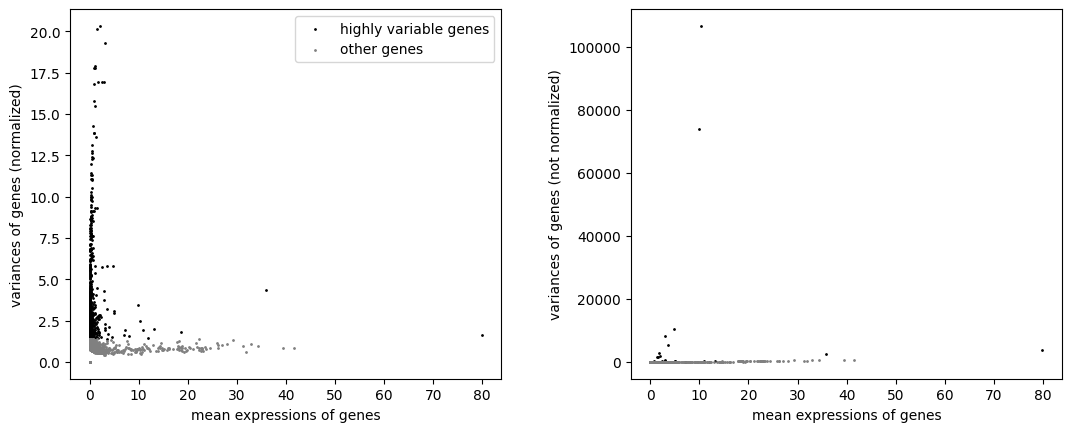

In [37]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=1000)
sc.pl.highly_variable_genes(adata)

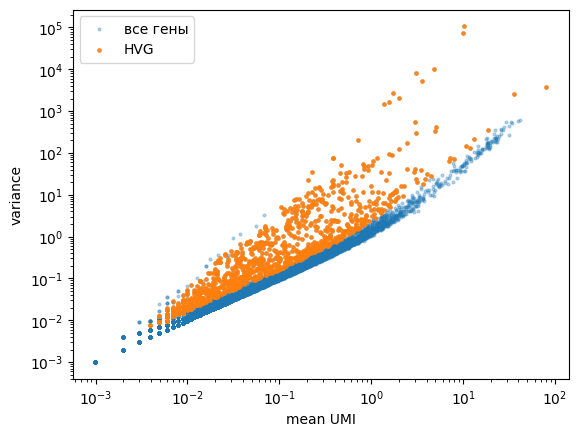

In [38]:
cnt = adata.layers["counts"]
mean_umi = np.asarray(cnt.mean(axis=0)).ravel()
adata.var["mean_umi"] = mean_umi
is_hvg = adata.var["highly_variable"].values

plt.scatter(adata.var["mean_umi"], adata.var["variances"],
                s=4, alpha=0.3, label="все гены")
plt.scatter(adata.var.loc[is_hvg, "mean_umi"],
                adata.var.loc[is_hvg, "variances"],
                s=6, alpha=0.8, label="HVG")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("mean UMI")
plt.ylabel("variance")
plt.legend()

Если взять например 1000 генов, то получается, что мы выбираем практиески все гены с избыточной variance, например 500 будет недостаточно



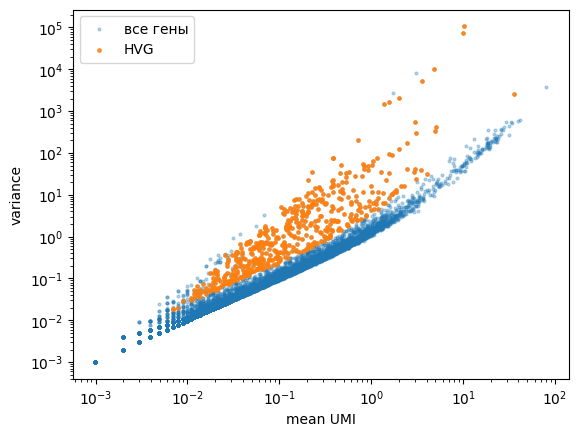

In [39]:
adata_500 = adata.copy()

sc.pp.highly_variable_genes(adata_500, layer="counts", flavor="seurat_v3", n_top_genes=500)



cnt = adata_500.layers["counts"]
mean_umi = np.asarray(cnt.mean(axis=0)).ravel()
adata_500.var["mean_umi"] = mean_umi
is_hvg = adata_500.var["highly_variable"].values

plt.scatter(adata_500.var["mean_umi"], adata_500.var["variances"],
                s=4, alpha=0.3, label="все гены")
plt.scatter(adata_500.var.loc[is_hvg, "mean_umi"],
                adata_500.var.loc[is_hvg, "variances"],
                s=6, alpha=0.8, label="HVG")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("mean UMI")
plt.ylabel("variance")
plt.legend()

Видно, что есть гены, с значительно более высокой дисперсией относительно пуассоновской модели, но они не попадают в HVG

In [40]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

PCA

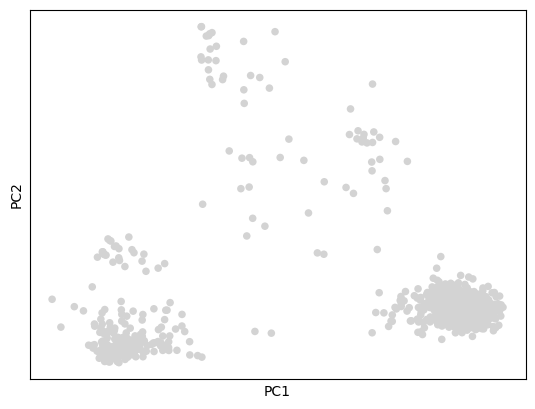

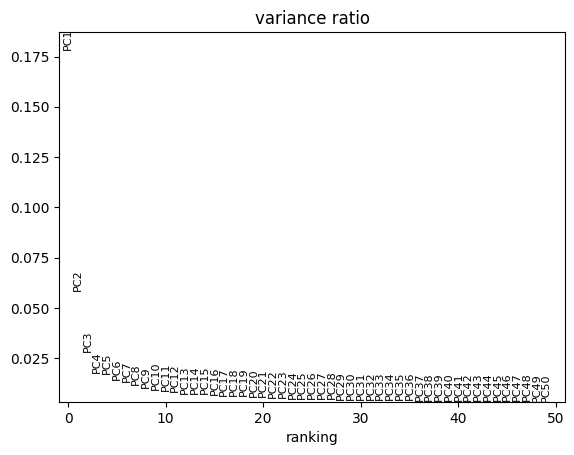

In [45]:
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable")
sc.pl.pca(
        adata,
        show=True
    )
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=False)

Значимый вклад вносят первые пять компонент - вместе они объясняют:

In [46]:
np.sum(adata.uns['pca']['variance_ratio'][:5])

np.float32(0.2998668)

30% Дисперсии

Построение графа и Leiden

Как было показано выше, основной вклад вносят первые пять компонент - возьмем с запасом 10. Число соседей для графа и resolution для Лейдена будем подбирать

In [47]:
n_neighbors_list = [5, 10, 20, 25, 30]
n_pcs = 10

/tmp/ipykernel_2218/3691736803.py:3: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1, key_added=f"leiden_n{n}", random_state=42)


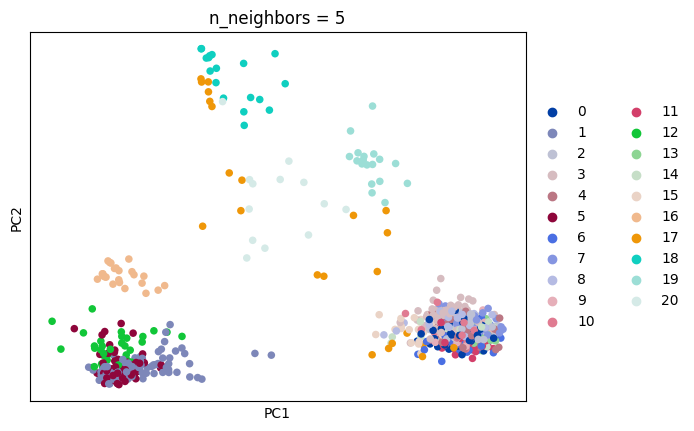

/tmp/ipykernel_2218/3691736803.py:3: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1, key_added=f"leiden_n{n}", random_state=42)


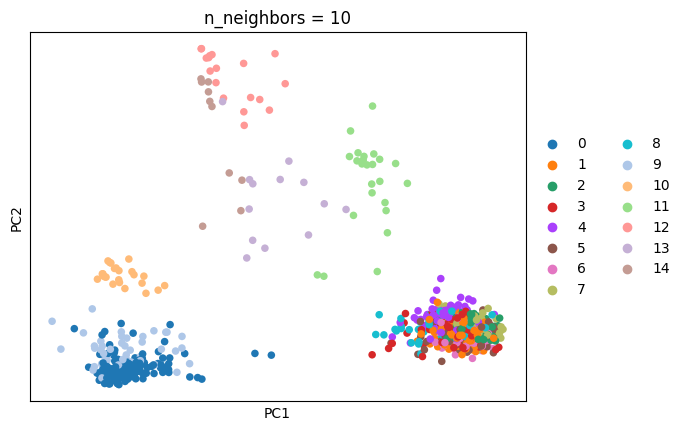

/tmp/ipykernel_2218/3691736803.py:3: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1, key_added=f"leiden_n{n}", random_state=42)


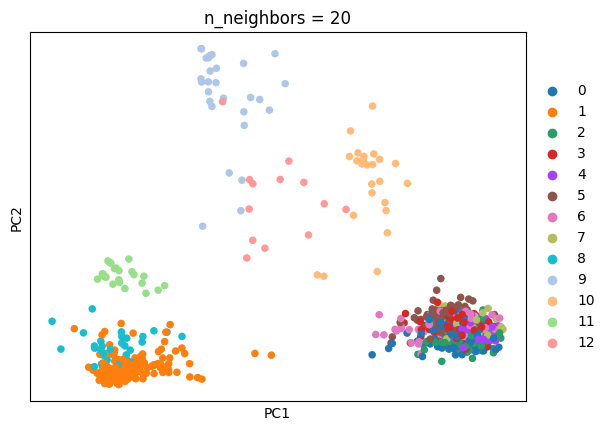

/tmp/ipykernel_2218/3691736803.py:3: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1, key_added=f"leiden_n{n}", random_state=42)


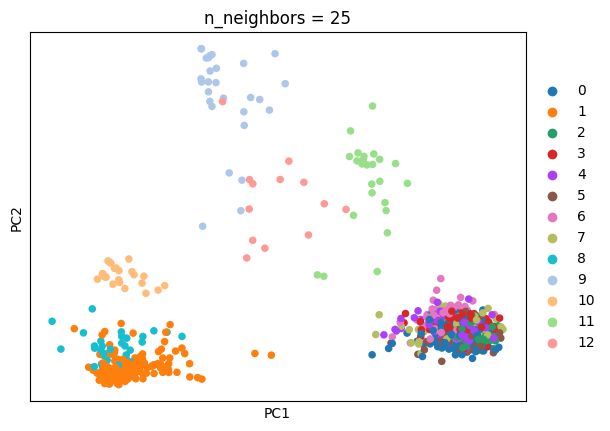

/tmp/ipykernel_2218/3691736803.py:3: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1, key_added=f"leiden_n{n}", random_state=42)


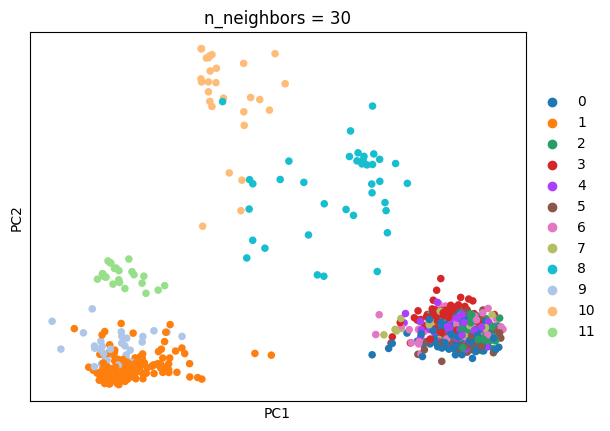

In [48]:
for n in n_neighbors_list:
    sc.pp.neighbors(adata, n_neighbors=n, n_pcs=n_pcs, random_state=42)
    sc.tl.leiden(adata, resolution=1, key_added=f"leiden_n{n}", random_state=42)

    sc.pl.pca(
        adata,
        color=f"leiden_n{n}",
        title=f"n_neighbors = {n}",
        show=True
    )

Скорее всего стоит взять число соседей 20-25 и понизить разрешение

/tmp/ipykernel_2218/2789409075.py:7: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=res, key_added=f"leiden_res{res}", random_state=42)


Resolution 0.2: 4 кластеров. Самый маленький: 24 клеток (2.4%)


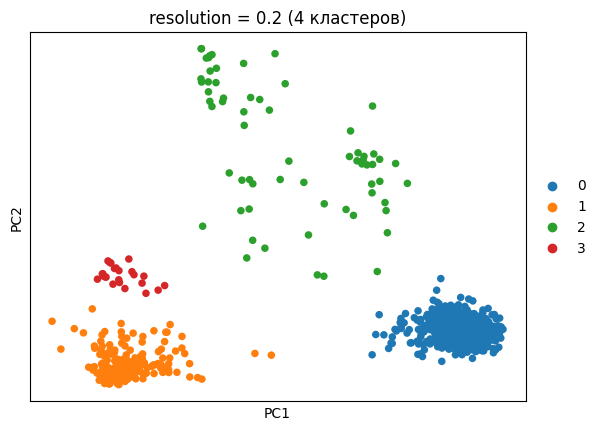

/tmp/ipykernel_2218/2789409075.py:7: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=res, key_added=f"leiden_res{res}", random_state=42)


Resolution 0.5: 8 кластеров. Самый маленький: 28 клеток (2.8%)


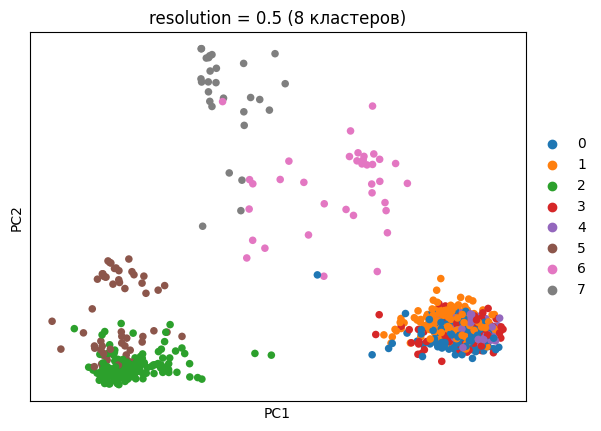

/tmp/ipykernel_2218/2789409075.py:7: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=res, key_added=f"leiden_res{res}", random_state=42)


Resolution 0.8: 11 кластеров. Самый маленький: 24 клеток (2.4%)


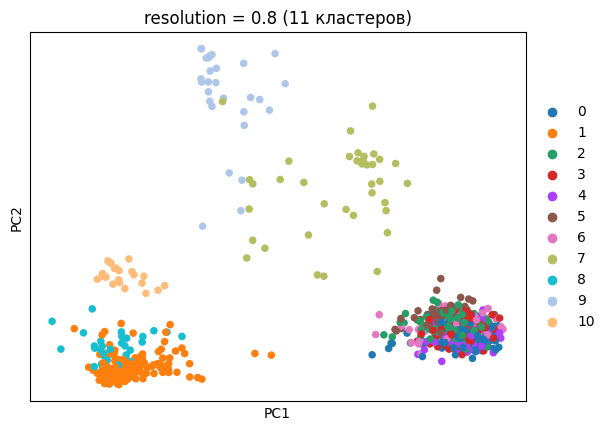

/tmp/ipykernel_2218/2789409075.py:7: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=res, key_added=f"leiden_res{res}", random_state=42)


Resolution 1.0: 13 кластеров. Самый маленький: 13 клеток (1.3%)


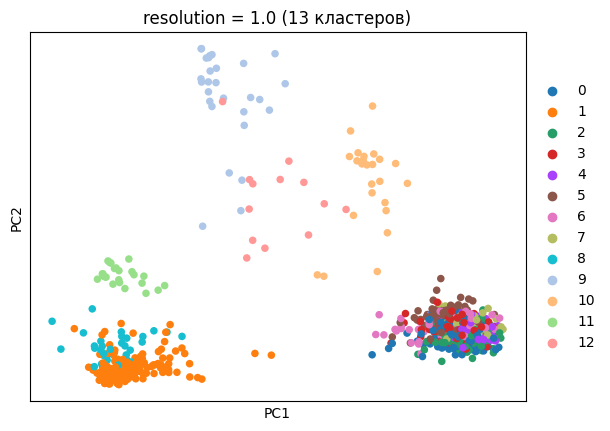

/tmp/ipykernel_2218/2789409075.py:7: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=res, key_added=f"leiden_res{res}", random_state=42)


Resolution 1.5: 18 кластеров. Самый маленький: 13 клеток (1.3%)


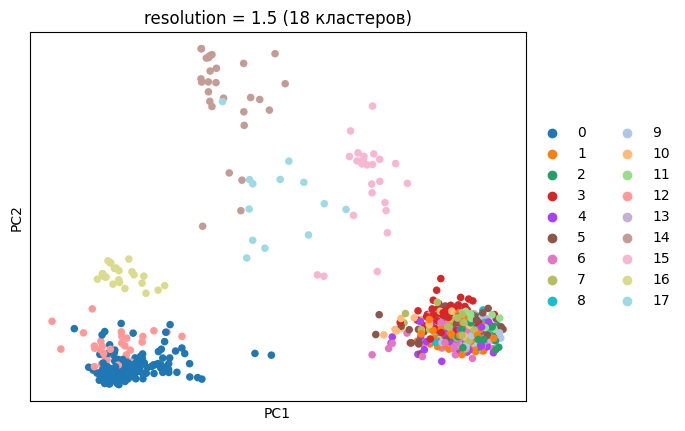

In [50]:
sc.pp.neighbors(adata, n_neighbors=20, n_pcs=n_pcs, random_state=42)


resolutions = [0.2, 0.5, 0.8, 1.0, 1.5]

for res in resolutions:
    sc.tl.leiden(adata, resolution=res, key_added=f"leiden_res{res}", random_state=42)

    n_clusters = adata.obs[f"leiden_res{res}"].nunique()

    min_cluster_size = adata.obs[f"leiden_res{res}"].value_counts().min()
    min_pct = (min_cluster_size / adata.n_obs) * 100

    print(f"Resolution {res}: {n_clusters} кластеров. Самый маленький: {min_cluster_size} клеток ({min_pct:.1f}%)")
    sc.tl.pca(adata, random_state=42)
    sc.pl.pca(
        adata,
        color=f"leiden_res{res}",
        title=f"resolution = {res} ({n_clusters} кластеров)",
        show=True
    )


Остановимся на варианте с разрешением 0.2 - получается 4 четко различимых кластера

Визуализация с UMAP и t-SNE

In [51]:
sc.tl.tsne(adata, n_pcs=15, random_state=42)

--- UMAP ---


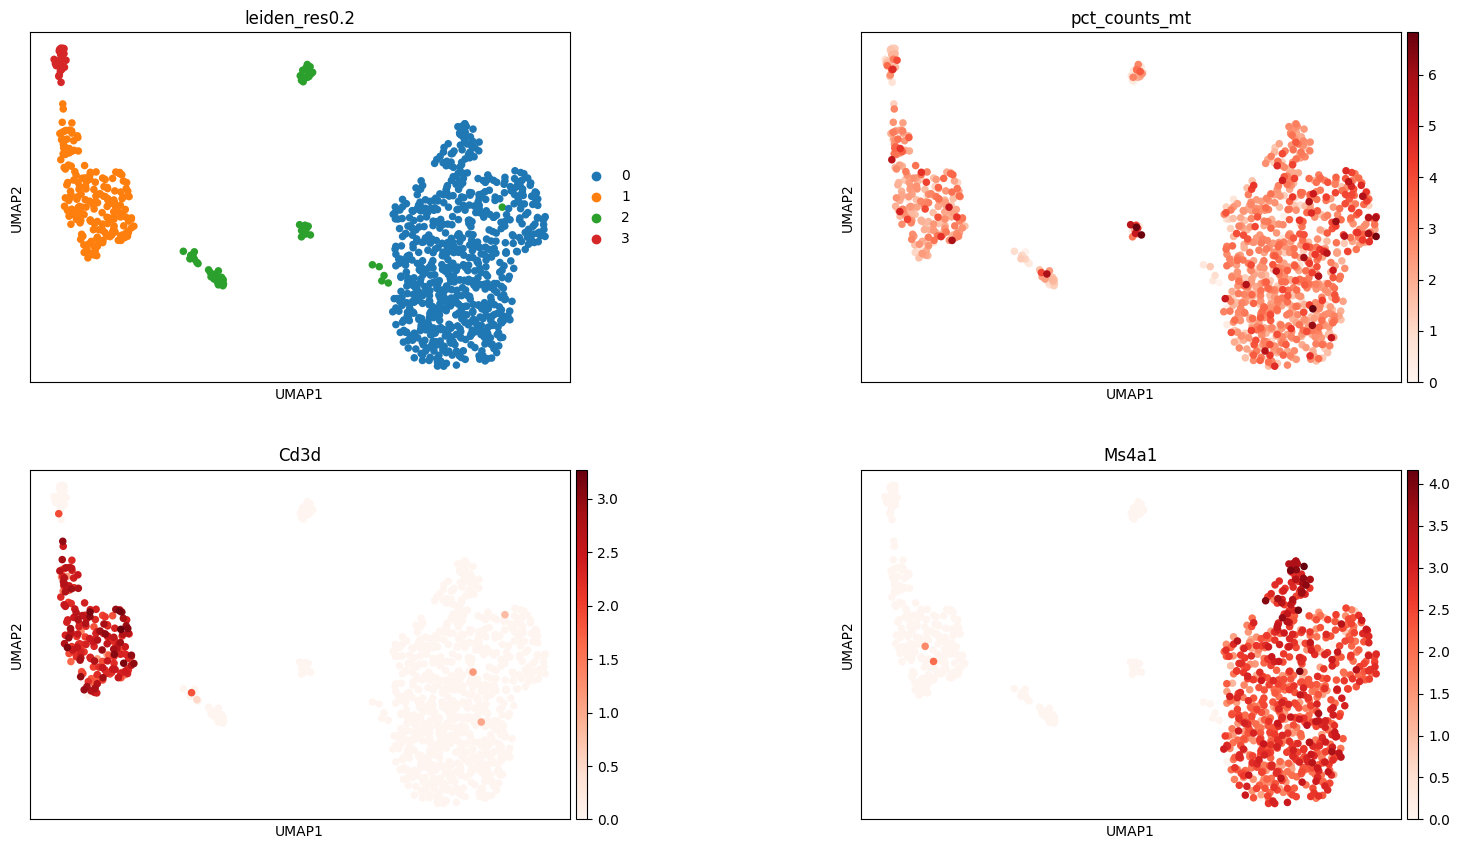

--- t-SNE ---


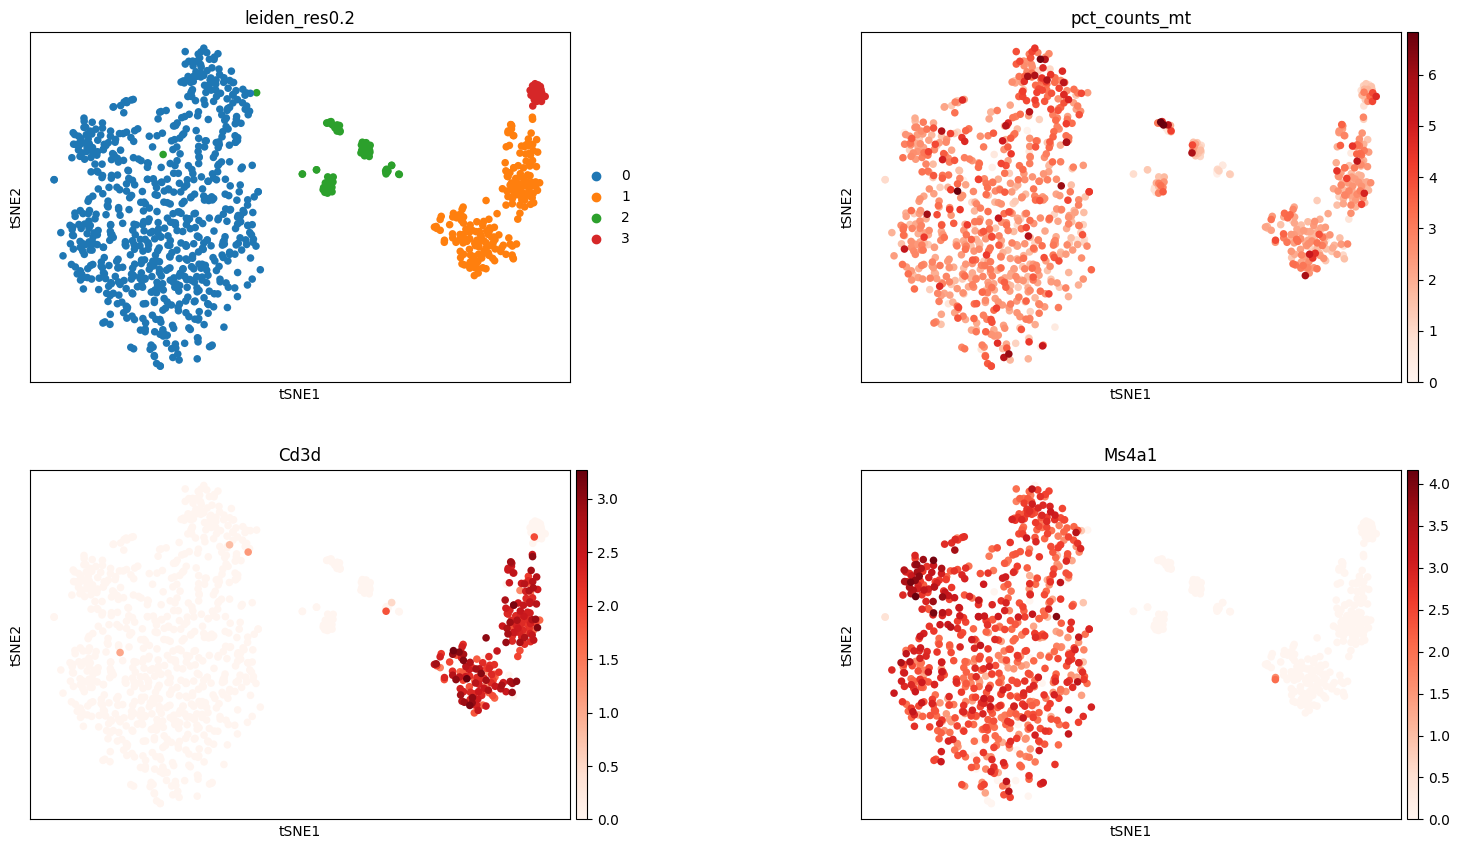

In [52]:
print("--- UMAP ---")
sc.pl.umap(
    adata,
    color=["leiden_res0.2", "pct_counts_mt", "Cd3d", "Ms4a1"],
    ncols=2,
    wspace=0.4,
    cmap="Reds"
)

print("--- t-SNE ---")
sc.pl.tsne(
    adata,
    color=["leiden_res0.2", "pct_counts_mt", "Cd3d", "Ms4a1"],
    ncols=2,
    wspace=0.4,
    cmap="Reds"
)

Можно заметить, что хотя UMAP и t-SNE по-разному представляют кластеры (в частности связность) - общее разделение почти совпадает. Но у t-SNE кластер 4 сгруппировался чуть лучше

Можно посмотреть на 2 гена. Экспрессия строго локализована в определенных кластерах. Cd3d (маркер T-клеток) светится в одной группе, а Ms4a1 (маркер B-клеток) — в совершенно другой. Это доказывает, что алгоритм Leiden корректно сгруппировал клетки по их биологии. Однако, нельзя утверждать что один кластер представляет собой одну группу клеток - например это могут быть близкие подтипы (очень разная экспрессия может быть у наивных и активированных клеток), которые не получилось разделить.

Еще нельзя делать выводы по дифференциальной экспрессии - для этого нужно проводить статистический тест

Нельзя экстраполировать на всю ткань (смотрим не на все клетки и только те, которые попали в секвенирование)

Посмотрим больше генов

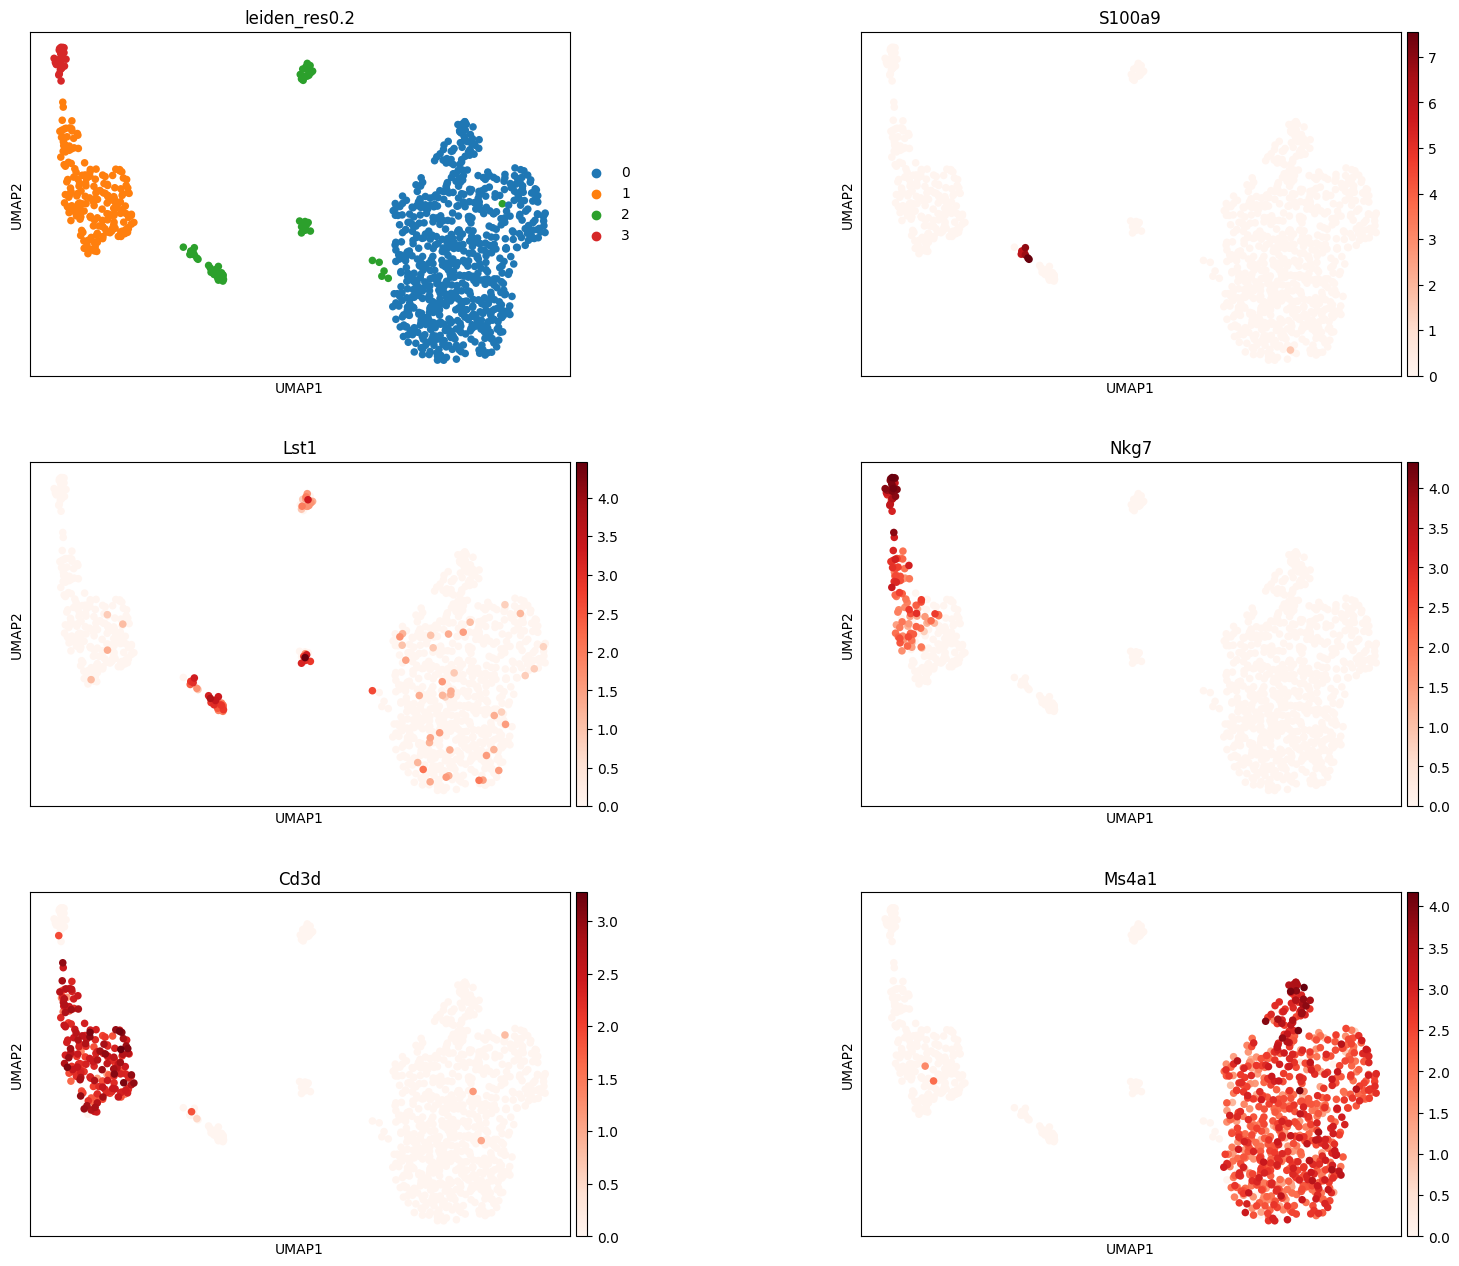

In [53]:
marker_genes = ["S100a9", "Lst1", "Nkg7", "Cd3d", "Ms4a1"]


sc.pl.umap(
    adata,
    color=["leiden_res0.2", "S100a9", "Lst1", "Nkg7", "Cd3d", "Ms4a1"],
    ncols=2,
    wspace=0.4,
    cmap="Reds"
)

S100a9 (маркер миелоидов):
Экспрессия достаточно слабо выражена, есть только в отдельных клетках в втором кластере

Lst1 (маркер миелоидов):
Также светится в кластере 2 и в некоторых клетках в других кластерах. Это ген, ассоциированный с клетками врожденного иммунитета (макрофаги, дендритные клетки).

Nkg7 (маркер NK-клеток):
Очень выражен в третьем кластере и немного в первом. Это классический маркер цитотоксических гранул NK-клеток (и некоторых T-киллеров).

Cd3d (маркер T-клеток):
Выражен в первом кластере Это компонент Т-клеточного рецептора — маркер T-лимфоцитов.

Ms4a1 (маркер B-клеток):
Полностью весь кластер 0. Это CD20 — классический маркер B-лимфоцитов.

Анализ экспрессии маркерных генов на UMAP-визуализации позволяет предположить наличие следующих популяций в клетках селезенки мыши:

T-лимфоциты: Кластер 1 характеризуется высокой экспрессией гена Cd3d (компонент Т-клеточного рецептора).

NK-клетки (натуральные киллеры): Обособленный кластер 3 показывает исключительную экспрессию гена Nkg7 (маркер цитотоксических гранул)

B-лимфоциты: Кластер 0 демонстрируют высокую экспрессию Ms4a1 - классического маркера В-клеток (при этом вероятно можно выделить субпопуляции В-клеток при более детальном анализе)

Тем не менее, кластеры нельзя однозначно относить отдельным клеточным типам, так как их границы областей клеток и границы кластеров не являются полностью совпадающими, часть клеток могла быть неверно отнесена к другому кластеру. Так же возможна значительная гетерогенность внутри кластеров (субпопуляции В-клеток например)

Для точной аннотации требуется как минимум анализ дифференциальной экспрессии генов клетками разных кластеров.